# 🏛️ UNIVERSIDAD NACIONAL DE SAN ANTONIO ABAD DEL CUSCO
### Facultad de Ingeniería Civil — Laboratorio de Materiales y Concreto
**Asignatura:** Tecnología de Materiales (IC151)  
**Docente:** ______________________________ | **Grupo / Brigada:** ______________________________  
**Semestre:** 2026-II  

---

# 🔬 PRÁCTICA N.° 9 (TM-09): Dimensionamiento, Alabeo de Ladrillos y Construcción de Pilas
### Cuaderno Interactivo de Procesamiento y Control Normativo

> **Normativa Técnica Aplicable:**  
> **NTP 399.613:2017** | **RNE E.070 (Tabla 1, num. 5.3 y 10.4 b)** | **NTP 399.605:2018**

---

### 🎯 Objetivos de la Práctica
1. Evaluar variación dimensional y alabeo en 10 unidades de arcilla según RNE E.070 Tabla 1.
2. Verificar si la unidad es sólida (área de vacíos <= 30 % según E.070 num. 5.3) o hueca/tubular.
3. Registrar la construcción de las 3 pilas de 3 hiladas con riego previo para ensayo a los 28 días en TM-12.

## ⚙️ 1. Conexión con el Motor de Cálculo (`civillab_unsaac`)
Presiona **Ejecutar (▶)** en la siguiente celda antes de comenzar. Conecta las fórmulas normativas de la UNSAAC, tablas y graficadores.

In [ ]:
# CIVILLAB_WEB_PRELOAD: prepara el navegador (solo versión web)
%pip install -q openpyxl


In [1]:
# ==============================================================================
# CONEXIÓN CON LA LIBRERÍA DEL LABORATORIO (Ejecutar primero, no modificar)
# ==============================================================================
try:
    import civillab_unsaac as lab
except ModuleNotFoundError:
    # Si la librería aún no está instalada, la ubicamos automáticamente en el proyecto
    import sys
    from pathlib import Path
    raices = [
        Path.cwd(),
        *list(Path.cwd().parents)[:3],
        Path.cwd() / "08_SOFTWARE_LABORATORIO",
        Path.cwd() / "0003_UNSAAC_DOCENCIA" / "08_SOFTWARE_LABORATORIO",
    ]
    for r in raices:
        if (r / "civillab_unsaac").is_dir():
            sys.path.insert(0, str(r))
            break
    import civillab_unsaac as lab

from pathlib import Path
from civillab_unsaac import *
import matplotlib
try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

try:
    from IPython.display import display
except ImportError:
    display = print

# Carpeta limpia para gráficos y fichas Excel de salida
_pkg_root = Path(lab.__file__).resolve().parents[1]
DIR_SALIDA = (_pkg_root / "fichas_generadas") if (_pkg_root / "notebooks").is_dir() else (Path.cwd() / "fichas_generadas")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

print("✓ Suite CivilLab UNSAAC conectada y lista para calcular.")

✓ Suite CivilLab UNSAAC conectada y lista para calcular.


---
## 🧱 2. Medición de 10 Unidades y Porcentaje de Vacíos

In [2]:
ladrillos_10 = [
    {"codigo": "L-01", "largo": 23.8, "ancho": 12.9, "alto": 8.9, "alabeo_mm": 2.0},
    {"codigo": "L-02", "largo": 24.1, "ancho": 13.1, "alto": 9.1, "alabeo_mm": 3.0},
    {"codigo": "L-03", "largo": 23.9, "ancho": 12.8, "alto": 8.8, "alabeo_mm": 2.5},
    {"codigo": "L-04", "largo": 24.2, "ancho": 13.0, "alto": 9.0, "alabeo_mm": 4.0},
    {"codigo": "L-05", "largo": 23.7, "ancho": 12.7, "alto": 8.9, "alabeo_mm": 3.0},
    {"codigo": "L-06", "largo": 24.0, "ancho": 13.2, "alto": 9.2, "alabeo_mm": 2.0},
    {"codigo": "L-07", "largo": 23.9, "ancho": 12.9, "alto": 9.0, "alabeo_mm": 1.5},
    {"codigo": "L-08", "largo": 24.1, "ancho": 13.0, "alto": 8.9, "alabeo_mm": 3.5},
    {"codigo": "L-09", "largo": 23.8, "ancho": 12.8, "alto": 8.8, "alabeo_mm": 2.5},
    {"codigo": "L-10", "largo": 24.0, "ancho": 13.1, "alto": 9.1, "alabeo_mm": 3.0},
]

# Medición de vacíos (volumen sólido con arena o inmersión)
datos_vacios = [
    {"codigo": "VAC-01", "largo_cm": 23.9, "ancho_cm": 12.9, "alto_cm": 9.0, "volumen_neto_cm3": 2080.0},
    {"codigo": "VAC-02", "largo_cm": 24.0, "ancho_cm": 13.0, "alto_cm": 9.0, "volumen_neto_cm3": 2110.0},
    {"codigo": "VAC-03", "largo_cm": 23.8, "ancho_cm": 12.8, "alto_cm": 8.9, "volumen_neto_cm3": 2045.0},
]
vacios = EnsayoVaciosLadrillo(datos_vacios, ladrillera="Ladrillera en estudio")

ladrillo = LadrilloCalidad(
    dimensiones_medidas=ladrillos_10,
    dim_nominales=(24.0, 13.0, 9.0),
    alabeos_mm=[x["alabeo_mm"] for x in ladrillos_10],
    porc_vacios=vacios.vacios_promedio,
    ladrillera="Ladrillera en estudio (San Jerónimo)",
)

display(pd.DataFrame(ladrillos_10))
display(vacios.df)
print("\n" + vacios.diagnostico_tecnico())
print("\n" + ladrillo.diagnostico_tecnico())


=== ENSAYO DE PORCENTAJE DE VACÍOS (RNE E.070 num. 5.3 / ASTM C67) ===
Ladrillera: Ladrillera en estudio | Unidades ensayadas: 3
• Porcentaje de vacíos promedio: 24.8 %
• Límite normativo para muros portantes: Máximo 30.0 % (Unidad Sólida)
DICTAMEN ESTRUCTURAL: Unidad Sólida (Apta para muros portantes sísmicos)

=== EVALUACIÓN GEOMÉTRICA DE LADRILLOS (RNE E.070 TABLA 1) ===
Ladrillera: Ladrillera en estudio (San Jerónimo) | Unidades ensayadas: 10
Dimensiones Nominales: 24.0 x 13.0 x 9.0 cm
Dimensiones Promedio:  23.95 x 12.95 x 8.97 cm
• Variación de Largo: 0.2 % | Ancho: 0.4 % | Alto: 0.3 %
• Alabeo máximo medido: 4.0 mm
• Porcentaje de vacíos: 24.8 % -> SÓLIDA (<= 30%)

CLASIFICACIÓN GEOMÉTRICA E.070: Ladrillo Tipo IV (Uso estructural muros portantes sísmicos)


,codigo,largo,ancho,alto,alabeo_mm
0,L-01,23.8,12.9,8.9,2.0
1,L-02,24.1,13.1,9.1,3.0
2,L-03,23.9,12.8,8.8,2.5
3,L-04,24.2,13.0,9.0,4.0
4,L-05,23.7,12.7,8.9,3.0
5,L-06,24.0,13.2,9.2,2.0
6,L-07,23.9,12.9,9.0,1.5
7,L-08,24.1,13.0,8.9,3.5
8,L-09,23.8,12.8,8.8,2.5
9,L-10,24.0,13.1,9.1,3.0


,codigo,largo_cm,ancho_cm,alto_cm,vol_bruto_cm3,vol_neto_cm3,vol_vacios_cm3,porc_vacios,clasificacion_seccion
0,VAC-01,23.9,12.9,9.0,2774.8,2080.0,694.8,25.0,Sólida / Maciza
1,VAC-02,24.0,13.0,9.0,2808.0,2110.0,698.0,24.9,Sólida / Maciza
2,VAC-03,23.8,12.8,8.9,2711.3,2045.0,666.3,24.6,Sólida / Maciza


---
## 📈 3. Gráfico, Construcción de Pilas y Exportación Excel

=== REGISTRO DE CONSTRUCCIÓN DE PILAS (PARA PRÁCTICA TM-12) ===

[OK] Ficha Excel generada en: E:\00_OFI_PRESUPUESTOS_progra\00_PLANES\0003_UNSAAC_DOCENCIA\0003_UNSAAC_DOCENCIA\08_SOFTWARE_LABORATORIO\fichas_generadas\TM-09_Ficha_Calidad_Ladrillo_E070.xlsx


,Pila,Fecha Construcción,Mortero,Riego Previo (E.070 10.4 b),Junta (mm),Curado
0,PILA-01,2026-10-14,P2 (1:4),Sí (30 min previo),12,Bolsa hermética ≥ 28 días
1,PILA-02,2026-10-14,P2 (1:4),Sí (30 min previo),12,Bolsa hermética ≥ 28 días
2,PILA-03,2026-10-14,P2 (1:4),Sí (30 min previo),13,Bolsa hermética ≥ 28 días


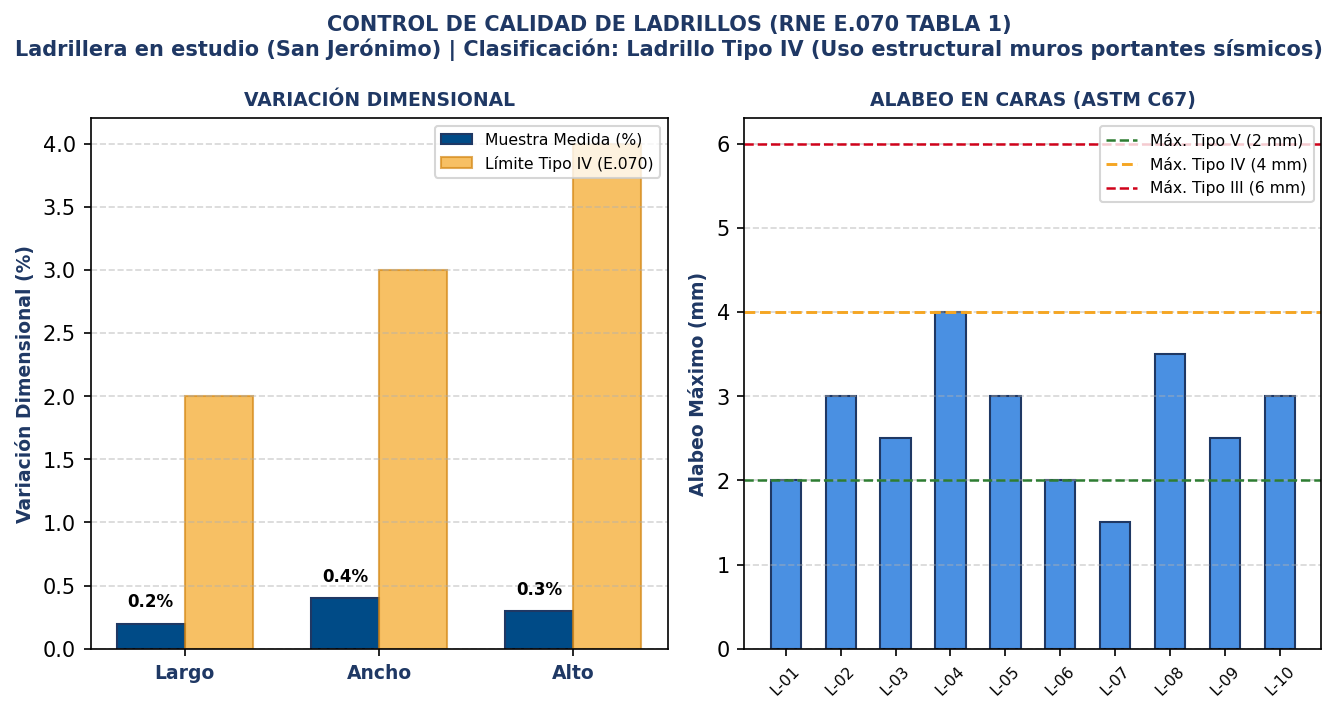

In [3]:
# 1. Registro de construcción de las 3 pilas de albañilería para TM-12:
registro_pilas = pd.DataFrame([
    {"Pila": "PILA-01", "Fecha Construcción": "2026-10-14", "Mortero": "P2 (1:4)", "Riego Previo (E.070 10.4 b)": "Sí (30 min previo)", "Junta (mm)": 12, "Curado": "Bolsa hermética ≥ 28 días"},
    {"Pila": "PILA-02", "Fecha Construcción": "2026-10-14", "Mortero": "P2 (1:4)", "Riego Previo (E.070 10.4 b)": "Sí (30 min previo)", "Junta (mm)": 12, "Curado": "Bolsa hermética ≥ 28 días"},
    {"Pila": "PILA-03", "Fecha Construcción": "2026-10-14", "Mortero": "P2 (1:4)", "Riego Previo (E.070 10.4 b)": "Sí (30 min previo)", "Junta (mm)": 13, "Curado": "Bolsa hermética ≥ 28 días"},
])
print("=== REGISTRO DE CONSTRUCCIÓN DE PILAS (PARA PRÁCTICA TM-12) ===")
display(registro_pilas)

# 2. Gráfico y exportación a Excel oficial
graficar_calidad_ladrillo(ladrillo, guardar_ruta=DIR_SALIDA / "TM-09_Calidad_Ladrillo.png", mostrar=True)
ruta_xlsx = exportar_ficha_ladrillos_e070_excel(ladrillo, DIR_SALIDA / "TM-09_Ficha_Calidad_Ladrillo_E070.xlsx", grupo="TM - Equipo 01")
print(f"\n[OK] Ficha Excel generada en: {ruta_xlsx}")